# 1. Chargement et Prétraitement du Dataset

Ce notebook réalise :
- L'import des bibliothèques nécessaires
- Le chargement et le filtrage des images par extension (jpeg, jpg, bmp, png)
- Le redimensionnement à 224×224 avec OpenCV
- L'exploration des classes et la visualisation
- Le contrôle de l'équilibre des classes
- La séparation X/y, la normalisation [0,1] et le split train/test
- L'encodage one-hot des labels

In [1]:
import os
import random
import warnings

import cv2
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from tensorflow.keras.utils import to_categorical

warnings.filterwarnings('ignore')

# Constantes
CATEGORIES = ['glioma', 'meningioma', 'notumor', 'pituitary']
IMG_SIZE = 224
VALID_EXTENSIONS = ('.jpeg', '.jpg', '.bmp', '.png')
RANDOM_STATE = 42

# Détection du répertoire projet (contenant data/classification/)
PROJECT_DIR = os.getcwd()
while not all(os.path.isdir(os.path.join(PROJECT_DIR, 'data', 'classification', c)) for c in CATEGORIES):
    parent = os.path.dirname(PROJECT_DIR)
    if parent == PROJECT_DIR:
        raise FileNotFoundError("Impossible de localiser data/classification/ avec les classes.")
    PROJECT_DIR = parent

DATA_DIR = os.path.join(PROJECT_DIR, 'data', 'classification')
print('PROJECT_DIR:', PROJECT_DIR)
print('DATA_DIR:', DATA_DIR)
print('Classes:', CATEGORIES)

I0000 00:00:1793132052.666386     703 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793132052.897706     703 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793132054.656594     703 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


PROJECT_DIR: /home/abdo/TumorClassificationAndDetection
DATA_DIR: /home/abdo/TumorClassificationAndDetection/data/classification
Classes: ['glioma', 'meningioma', 'notumor', 'pituitary']


In [1]:
import tensorflow as tf

print(tf.__version__)

I0000 00:00:1793133640.722447     732 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793133640.964443     732 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793133643.019499     732 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


2.22.0-rc0


In [2]:
# Chargement, filtrage par extension, redimensionnement
images = []
labels = []

for category in CATEGORIES:
    path = os.path.join(DATA_DIR, category)
    class_num = CATEGORIES.index(category)
    try:
        files = os.listdir(path)
    except Exception as e:
        print(f'Erreur accès dossier {path}: {e}')
        continue
    for img_name in files:
        if not img_name.lower().endswith(VALID_EXTENSIONS):
            continue
        try:
            img_path = os.path.join(path, img_name)
            img_array = cv2.imread(img_path)
            if img_array is None:
                continue
            img_resized = cv2.resize(img_array, (IMG_SIZE, IMG_SIZE))
            images.append(img_resized)
            labels.append(class_num)
        except Exception as e:
            print(f"Erreur avec l'image {img_name}: {e}")

# Mélange pour éviter les biais
data_pairs = list(zip(images, labels))
random.shuffle(data_pairs)
images, labels = zip(*data_pairs)

print(f'Total images chargées: {len(images)}')

Total images chargées: 7023


In [3]:
# Conversion en tableaux NumPy
X = np.array(images, dtype=np.float32)
y = np.array(labels)

print('X shape:', X.shape, '| y shape:', y.shape)

X shape: (7023, 224, 224, 3) | y shape: (7023,)


glioma: 1621
meningioma: 1645
notumor: 2000
pituitary: 1757


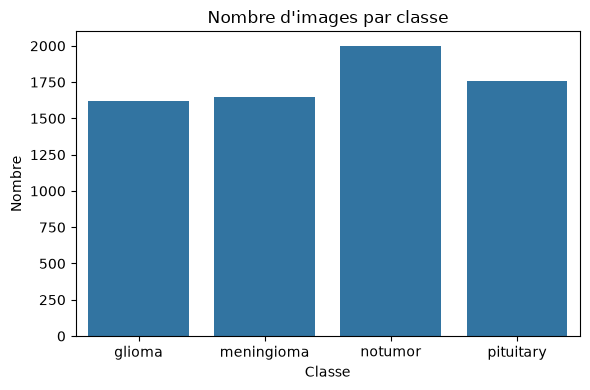

In [4]:
# Comptage par classe
counts = np.bincount(y)
for i, c in enumerate(CATEGORIES):
    print(f'{c}: {counts[i] if i < len(counts) else 0}')

# Graphique
plt.figure(figsize=(6,4))
sns.barplot(x=CATEGORIES, y=counts)
plt.title('Nombre d\'images par classe')
plt.xlabel('Classe')
plt.ylabel('Nombre')
plt.tight_layout()
plt.show()

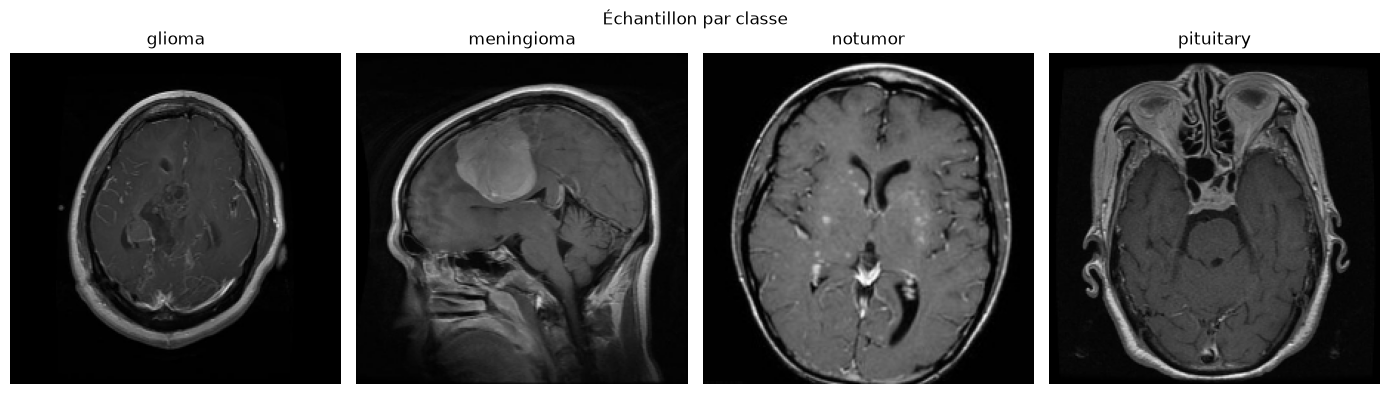

In [5]:
# Afficher un échantillon par classe
fig, axes = plt.subplots(1, len(CATEGORIES), figsize=(14, 4))
for i, cat in enumerate(CATEGORIES):
    idxs = np.where(y == i)[0]
    if len(idxs) > 0:
        j = idxs[0]
        img = X[j].astype(np.uint8)
        axes[i].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[i].set_title(cat)
    axes[i].axis('off')
plt.suptitle('Échantillon par classe')
plt.tight_layout()
plt.show()

In [6]:
# Vérification de l'équilibre
total = len(y)
counts = np.bincount(y)
props = counts / total if total > 0 else counts

for i, c in enumerate(CATEGORIES):
    p = props[i] if i < len(props) else 0
    print(f'{c}: {int(counts[i])} ({p:.3f})')

print('\nNote: déséquilibre léger observé. Stratégie recommandée: class_weight pour préserver données.')

# Calcul des poids de classe (inverses de fréquence)
from sklearn.utils.class_weight import compute_class_weight

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.arange(len(CATEGORIES)),
    y=y
)
class_weight_dict = {i: float(class_weights[i]) for i in range(len(class_weights))}
print('class_weight_dict:', class_weight_dict)

glioma: 1621 (0.231)
meningioma: 1645 (0.234)
notumor: 2000 (0.285)
pituitary: 1757 (0.250)

Note: déséquilibre léger observé. Stratégie recommandée: class_weight pour préserver données.
class_weight_dict: {0: 1.0831276989512646, 1: 1.067325227963526, 2: 0.877875, 3: 0.9992885600455321}


In [7]:


# 1. Encodage One-Hot des labels
y_cat = to_categorical(y, num_classes=len(CATEGORIES))

# 2. Première division : 70% Train et 30% temporaire
X_train, X_temp, y_train, y_temp, y_train_labels, y_temp_labels = train_test_split(
    X,
    y_cat,
    y,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y
)

# 3. Deuxième division : 15% Validation et 15% Test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp_labels
)

# 4. Affichage des dimensions
print("Après split :")
print("X_train:", X_train.shape, "y_train:", y_train.shape)
print("X_val:  ", X_val.shape,   "y_val:  ", y_val.shape)
print("X_test: ", X_test.shape,  "y_test: ", y_test.shape)


Après split :
X_train: (4916, 224, 224, 3) y_train: (4916, 4)
X_val:   (1053, 224, 224, 3) y_val:   (1053, 4)
X_test:  (1054, 224, 224, 3) y_test:  (1054, 4)


In [ ]:
# Normalisation des pixels dans [0,1]
X_train = X_train / 255.0
X_val = X_val / 255.0 
X_test  = X_test  / 255.0

print('Min/Max après normalisation:', X_train.min(), X_train.max())

## Résumé
- Images chargées, filtrées par extension, redimensionnées à **224×224**
- Données mélangées et converties en **NumPy**
- Distribution des classes visualisée, **poids de classe** calculés (rééquilibrage via `class_weight`)
- Labels encodés en **one-hot** (`to_categorical`)
- Split stratifié **train/validation/test (70/15/15)**
- Pixels normalisés dans **[0,1]**